# Pair 4 — FLUX.2 klein 4B evaluation

**Organisation:** Amazon retail  
**Task:** Generate promotional product images from product descriptions  
**Model:** FLUX.2 klein 4B (locally downloaded SDNQ quantised checkpoint)

## Objective

I used FLUX.2 klein 4B to generate images for the same 30 Amazon product prompts used in the Z-Image-Turbo experiment. Both models use the same resolution and seed values. I recorded image-generation time and saved each output for the manual assessment in `Comparison.ipynb`.

This experiment uses a pretrained checkpoint for inference only. No fine-tuning or training was performed.

## 1. Setup


In [1]:
from pathlib import Path
import json
import time
import pandas as pd
import torch
from PIL import Image
from IPython.display import display

HERE = Path.cwd().resolve()
if (HERE / "prompts.csv").exists():
    BASE = HERE
elif (HERE / "Models" / "Pair_04" / "prompts.csv").exists():
    BASE = HERE / "Models" / "Pair_04"
else:
    raise FileNotFoundError("Run this notebook from Pair_04 or the repository root.")

PROMPTS_FILE = BASE / "prompts.csv"
OUT_DIR = BASE / "results" / "FLUX2_Klein"
IMAGE_DIR = OUT_DIR / "images"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

# Same resolution and seed identifiers as Z-Image-Turbo
HEIGHT = 512
WIDTH = 512
STEPS = 4
GUIDANCE = 1.0
SEED = 42

# Find the locally downloaded FLUX checkpoint
MODEL_ROOT = BASE / "models"
model_candidates = [
    MODEL_ROOT / "FLUX2_Klein",
    MODEL_ROOT / "FLUX2_klein_4B",
    MODEL_ROOT / "FLUX.2-klein-4B",
    MODEL_ROOT / "FLUX.2-klein-4B-SDNQ-4bit-dynamic",
    MODEL_ROOT / "checkpoints" / "FLUX2_klein_4B",
]
MODEL_DIR = next((p for p in model_candidates if (p / "model_index.json").exists()), None)
if MODEL_DIR is None:
    matches = [p.parent for p in MODEL_ROOT.rglob("model_index.json") if "flux" in str(p.parent).lower()]
    if len(matches) == 1:
        MODEL_DIR = matches[0]
    else:
        raise FileNotFoundError(
            f"Could not identify one FLUX Diffusers checkpoint in {MODEL_ROOT}. "
            f"Found: {matches}. Set MODEL_DIR to the folder containing model_index.json."
        )

print("Pair 4:", BASE)
print("Checkpoint:", MODEL_DIR)
print("Output folder:", OUT_DIR)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Pair 4: C:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\Models\Pair_04
Checkpoint: C:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\Models\Pair_04\models\FLUX2-klein-4B
Output folder: C:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\Models\Pair_04\results\FLUX2_Klein
CUDA available: True
GPU: NVIDIA GeForce RTX 3070 Ti Laptop GPU


## 2. Load the evaluation prompts

The 30 prompts come from the same ABO-based `prompts.csv` used by Z-Image-Turbo. I do not edit the prompts for this model.

In [2]:
df = pd.read_csv(PROMPTS_FILE)
assert "prompt" in df.columns, "prompts.csv needs a 'prompt' column"
assert len(df) == 30, f"Expected 30 prompts, found {len(df)}"
assert df["prompt"].notna().all(), "Some prompts are missing"

if "prompt_id" not in df.columns:
    df["prompt_id"] = [f"P{i:03d}" for i in range(1, len(df) + 1)]
assert df["prompt_id"].is_unique, "Prompt IDs must be unique"

# Confirm the Z-Image evaluation used these prompt IDs, if its results are present
Z_CSV = BASE / "results" / "Z_Image_Turbo" / "generation_results.csv"
if Z_CSV.exists():
    z_df = pd.read_csv(Z_CSV)
    assert set(z_df["prompt_id"].astype(str)) == set(df["prompt_id"].astype(str)), "Prompt ID mismatch with Z-Image"
    if "prompt" in z_df.columns:
        assert dict(zip(df["prompt_id"].astype(str), df["prompt"])) == dict(zip(z_df["prompt_id"].astype(str), z_df["prompt"])), "Prompts differ from Z-Image"
    if "seed" in z_df.columns:
        expected_seeds = dict(zip(df["prompt_id"].astype(str), [SEED + i for i in range(len(df))]))
        assert dict(zip(z_df["prompt_id"].astype(str), z_df["seed"].astype(int))) == expected_seeds, "Seeds differ from Z-Image"
    print("Confirmed prompt IDs, text and seeds against the Z-Image results.")

display(df[["prompt_id", "prompt"]].head(5))

Confirmed prompt IDs, text and seeds against the Z-Image results.


,prompt_id,prompt
0,P001,Professional ecommerce photograph of a large n...
1,P002,Premium retail product photograph of a pair of...
2,P003,Realistic commercial product photograph of a h...
3,P004,Clean children's clothing catalogue photograph...
4,P005,Studio product photo of a flexible silicone ba...


## 3. Load FLUX.2 klein

I load the locally downloaded Diffusers checkpoint, rather than downloading weights at run time. The SDNQ quantisation format requires importing `sdnq` first. I use CPU offloading because the GPU has 8 GB VRAM.

FLUX.2 klein 4B uses four inference steps and guidance 1.0 in its reference inference example. The different step counts are reported as a limitation when comparing latency, since each model uses its own recommended settings.

In [3]:
import diffusers
import sdnq  # registers the SDNQ layers

if not torch.cuda.is_available():
    raise RuntimeError("This evaluation requires a CUDA GPU.")

# This is the class specified for the distilled FLUX.2 klein checkpoint
pipe = diffusers.Flux2KleinPipeline.from_pretrained(
    str(MODEL_DIR),
    torch_dtype=torch.bfloat16,
    local_files_only=True,
)
pipe.enable_model_cpu_offload()
print("Loaded FLUX.2 klein from", MODEL_DIR)

# If your earlier smoke test needed extra memory-saving options,
# apply those same options here before running 30 prompts.

c:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\.venv-flux\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
SDNQ: Torch Compile is not available. Falling back to PyTorch Eager mode.
SDNQ: OpenVINO MM kernels are not available! Falling back to PyTorch Eager kernels for CPU device. Error message: No module named 'openvino'
SDNQ: Triton MM kernels are not available! Falling back to PyTorch Eager kernels. Error message: No module named 'triton'
SDNQ: Triton Scaled MM kernels are not available! Falling back to PyTorch Eager kernels. Error message: No module named 'triton'
c:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\.venv-flux\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0.

Loaded FLUX.2 klein from C:\Users\royay\OneDrive\Desktop\COMP8410\Assignment 1\COMP8410_A1_49128299\Models\Pair_04\models\FLUX2-klein-4B


## 4. Generate images and record inference time

I use one output per product. For prompt row `i`, the seed is `42 + i`, matching the Z-Image experiment. Timing starts immediately before generation and ends after CUDA synchronisation; it excludes model loading and image saving. Each result is saved immediately so the run can be resumed without regenerating finished images.

In [4]:
RESULTS_CSV = OUT_DIR / "generation_results.csv"
records = pd.read_csv(RESULTS_CSV).to_dict("records") if RESULTS_CSV.exists() else []

completed = {
    str(r["prompt_id"])
    for r in records
    if r.get("status") == "success" and (IMAGE_DIR / f"{r['prompt_id']}.png").exists()
}

for i, row in df.reset_index(drop=True).iterrows():
    prompt_id = str(row["prompt_id"])
    if prompt_id in completed:
        print(f"Skipping {prompt_id} (already generated)")
        continue

    prompt = str(row["prompt"])
    seed = SEED + i
    image_path = IMAGE_DIR / f"{prompt_id}.png"
    print(f"Generating {prompt_id} ({i + 1}/{len(df)})")

    try:
        generator = torch.Generator(device="cpu").manual_seed(seed)
        torch.cuda.synchronize()
        start = time.perf_counter()
        image = pipe(
            prompt=prompt,
            height=HEIGHT,
            width=WIDTH,
            num_inference_steps=STEPS,
            guidance_scale=GUIDANCE,
            generator=generator,
        ).images[0]
        torch.cuda.synchronize()
        seconds = time.perf_counter() - start
        image.save(image_path)
        status, error = "success", ""
        print(f"  saved {image_path.name} in {seconds:.2f}s")
    except Exception as exc:
        seconds = None
        status, error = "failed", str(exc)
        print(f"  ERROR: {error}")
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    records = [r for r in records if str(r["prompt_id"]) != prompt_id]
    records.append({
        "prompt_id": prompt_id,
        "item_id": row.get("item_id", ""),
        "model": "FLUX.2-klein-4B-SDNQ",
        "prompt": prompt,
        "seed": seed,
        "height": HEIGHT,
        "width": WIDTH,
        "steps": STEPS,
        "guidance_scale": GUIDANCE,
        "generation_seconds": seconds,
        "image_path": str(image_path.relative_to(BASE)) if status == "success" else "",
        "status": status,
        "error": error,
    })
    pd.DataFrame(records).to_csv(RESULTS_CSV, index=False)

results = pd.read_csv(RESULTS_CSV)
display(results[["prompt_id", "seed", "generation_seconds", "status"]])

Generating P001 (1/30)


100%|██████████| 4/4 [00:07<00:00,  1.81s/it]


  saved P001.png in 11.34s
Generating P002 (2/30)


100%|██████████| 4/4 [00:03<00:00,  1.23it/s]


  saved P002.png in 7.44s
Generating P003 (3/30)


100%|██████████| 4/4 [00:02<00:00,  1.47it/s]


... (52 outputs left out)

  saved P029.png in 5.08s
Generating P030 (30/30)


100%|██████████| 4/4 [00:02<00:00,  1.36it/s]


  saved P030.png in 5.08s


,prompt_id,seed,generation_seconds,status
0,P001,42,11.338217,success
1,P002,43,7.441969,success
2,P003,44,4.494684,success
3,P004,45,4.173995,success
4,P005,46,4.185725,success
5,P006,47,4.349234,success
6,P007,48,4.149116,success
7,P008,49,4.175903,success
8,P009,50,4.338412,success
9,P010,51,4.234750,success


## 5. Summary and example outputs

FLUX.2 klein successfully generated all 30 product images without failures. The mean generation time was 4.84 seconds, while the median was 4.53 seconds per image. Images were generated at 512 × 512 resolution using 4 inference steps on an NVIDIA RTX 3070 Ti Laptop GPU.

Compared with Z-Image-Turbo, which averaged 10.97 seconds per image, FLUX.2 klein was approximately 2.27 times faster. Both models completed all 30 generations successfully. However, this only measures inference performance, not image quality. I will compare the generated images using the same manual scoring rubric for both models.

,model,num_prompts,successful_images,failed_images,mean_generation_seconds,median_generation_seconds,height,width,steps,guidance_scale,base_seed
0,FLUX.2-klein-4B-SDNQ,30,30,0,4.837726,4.534306,512,512,4,1.0,42


P001


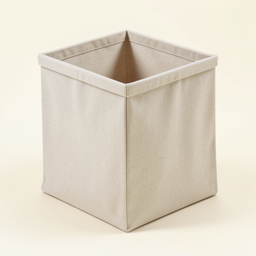

P002


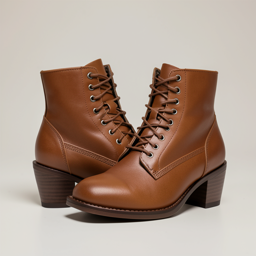

P003


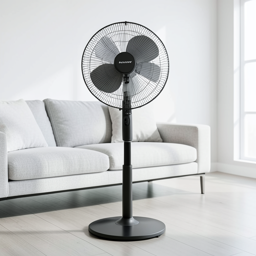

P004


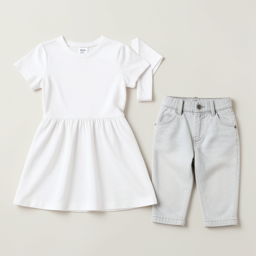

In [5]:
results = pd.read_csv(RESULTS_CSV)
success = results[results["status"] == "success"].copy()

summary = {
    "model": "FLUX.2-klein-4B-SDNQ",
    "checkpoint": str(MODEL_DIR),
    "num_prompts": len(df),
    "successful_images": len(success),
    "failed_images": len(df) - len(success),
    "mean_generation_seconds": float(success["generation_seconds"].mean()) if len(success) else None,
    "median_generation_seconds": float(success["generation_seconds"].median()) if len(success) else None,
    "height": HEIGHT,
    "width": WIDTH,
    "steps": STEPS,
    "guidance_scale": GUIDANCE,
    "base_seed": SEED,
    "pytorch_version": torch.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
}
with open(OUT_DIR / "summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

display(pd.DataFrame([summary]).drop(columns=["checkpoint", "pytorch_version", "gpu"]))

for prompt_id in success["prompt_id"].head(4):
    print(prompt_id)
    display(Image.open(IMAGE_DIR / f"{prompt_id}.png").resize((256, 256)))

## 6. Initial reflection

This experiment measures the ability of FLUX.2 klein to complete all 30 product-image generations and the time required on my laptop GPU. The generated outputs are saved for a later manual evaluation of prompt adherence, visual quality, product accuracy and suitability for Amazon advertising.

**Limitations:** The dataset contains only 30 products, with one seed per prompt. Matching seeds does not guarantee equivalent random noise across different architectures. Neither model receives reference product images, so visual fidelity to a real Amazon listing cannot be verified from text alone. The 4-bit checkpoint and CPU offloading may change performance compared with the original full-precision model. The recommended inference-step counts also differ between the two models.